# Walk-Rear Success Rate Curves

Plot eval episode success rate vs simulation steps (truncated to `STEP_BUDGET`) for `distill` (SCAMPER), `decoder_only` (MIMIC-MJX), and `scratch` (Scratch) walk-rear runs.

In [16]:
import csv
import re
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

matplotlib.rcParams["font.family"] = "DM Sans"

In [17]:
# --- Load and parse CSV ---
csv_path = "/home/mila/a/aidan.sirbu/SCAMPER/data/walk_rear.csv"
STEP_BUDGET = 5.6e8  # Truncate curves at or below this many simulation steps

# Pattern: Full_dm1.0_<training_mode>_s<seed>_<run_id>
# run_id is three underscore-separated numeric chunks (e.g. 260415_201750_210730)
# Lazy match for training_mode so it doesn't swallow the seed segment.
run_pattern = re.compile(r"^Full_dm1\.0_(.+?)_s(\d+)_(\d+_\d+_\d+)$")

with open(csv_path) as f:
    reader = csv.reader(f)
    header = next(reader)
    rows = list(reader)

# Find columns for each run's mean success metric (exclude __MIN/__MAX and _step columns)
runs = {}
for i, col in enumerate(header):
    if (
        col.endswith(" - eval/episode_success")
        and not col.endswith("__MIN")
        and not col.endswith("__MAX")
    ):
        run_name = col.split(" - ")[0]
        runs[run_name] = i

records = []
for run_name, col_idx in runs.items():
    m = run_pattern.match(run_name)
    if not m:
        print(f"Skipping unmatched run: {run_name}")
        continue
    mode = m.group(1)
    seed = int(m.group(2))
    run_id = m.group(3)
    for row in rows:
        step_str = row[0].strip()
        val_str = row[col_idx].strip()
        if not step_str or not val_str:
            continue
        step = float(step_str)
        if step > STEP_BUDGET:
            break
        records.append(
            {
                "num_steps": step,
                "training_mode": mode,
                "seed": seed,
                "run_id": run_id,
                "success_rate": float(val_str),
            }
        )

df = pd.DataFrame(records)

# Rename training modes
mode_rename = {
    "distill": "SCAMPER",
    "decoder_only": "MIMIC-MJX",
    "scratch": "Scratch",
}
df["Training Mode"] = df["training_mode"].map(mode_rename)

print(f"{df['run_id'].nunique()} runs, {len(df)} datapoints, max step={df['num_steps'].max():.2e}")
print(df.groupby("Training Mode")["seed"].nunique().rename("num_seeds"))
df.head()

12 runs, 444 datapoints, max step=5.54e+08
Training Mode
MIMIC-MJX    4
SCAMPER      4
Scratch      4
Name: num_seeds, dtype: int64


,num_steps,training_mode,seed,run_id,success_rate,Training Mode
0,0.0,distill,3,260415_201750_210730,0.0,SCAMPER
1,15400960.0,distill,3,260415_201750_210730,0.0,SCAMPER
2,30801920.0,distill,3,260415_201750_210730,0.0,SCAMPER
3,46202880.0,distill,3,260415_201750_210730,0.0,SCAMPER
4,61603840.0,distill,3,260415_201750_210730,0.0,SCAMPER


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/walk_rear_success_rate.[pdf|svg|png]


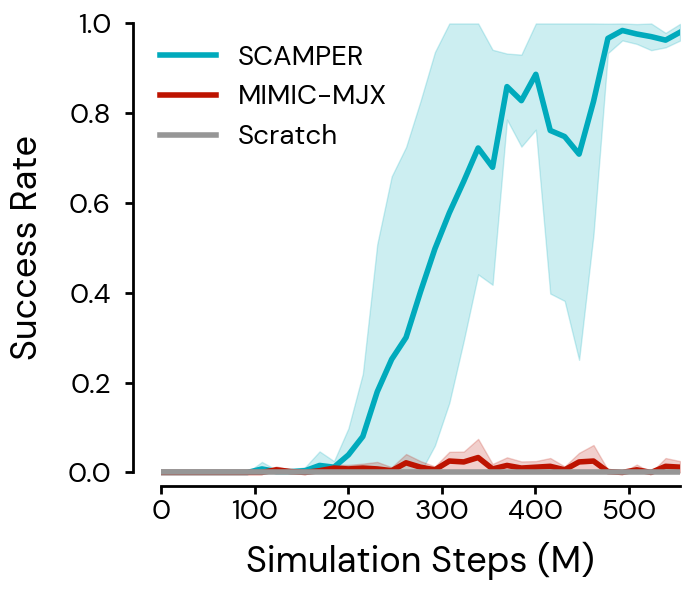

In [23]:
hue_order = ["SCAMPER", "MIMIC-MJX", "Scratch"]
palette = {
    "SCAMPER": tuple(c / 255 for c in (0, 170, 188)),
    "MIMIC-MJX": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}

save_name = "walk_rear_success_rate"

# Plot in millions of simulation steps for cleaner x-axis
df_plot = df.copy()
df_plot["sim_steps_M"] = df_plot["num_steps"] / 1e6

fig, ax_main = plt.subplots(figsize=(7, 6))

# --- Main plot ---
sns.lineplot(
    data=df_plot,
    x="sim_steps_M",
    y="success_rate",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    linewidth=4,
    ax=ax_main,
)

# Clip error band shading to [0, 1]
for child in ax_main.get_children():
    if isinstance(child, plt.matplotlib.collections.PolyCollection):
        for path in child.get_paths():
            path.vertices[:, 1] = np.clip(path.vertices[:, 1], 0, 1)

# X-axis spans up to the actual max plotted point (data is already truncated by STEP_BUDGET above)
x_data_max = float(df_plot["sim_steps_M"].max())

ax_main.set_xlim(0, x_data_max)
ax_main.set_xticks(np.arange(0, x_data_max + 1, 100))
ax_main.set_ylim(-0.03, 1.03)
ax_main.set_yticks(np.arange(0, 1.01, 0.2))

ax_main.set_xlabel("Simulation Steps (M)", fontsize=26, labelpad=12)
ax_main.set_ylabel("Success Rate", fontsize=26, labelpad=16)
ax_main.tick_params(labelsize=20, width=2, length=6)
ax_main.tick_params(axis="y", pad=10)

# Remove top and right spines
sns.despine(ax=ax_main)

# Bottom spine extends to the last plotted point (not just the last tick)
ax_main.spines["bottom"].set_bounds(0, x_data_max)
yticks = ax_main.get_yticks()
ax_main.spines["left"].set_bounds(yticks[0], yticks[-1])

# Shift y-axis spine to the left
ax_main.spines["left"].set_position(("outward", 20))

# Thicken the remaining spines
for spine in ["left", "bottom"]:
    ax_main.spines[spine].set_linewidth(2)

ax_main.legend(
    fontsize=20, frameon=False, loc="upper left", bbox_to_anchor=(-0.05, 0.98)
)

plt.tight_layout()

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()